# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.1 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.6 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.3 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,15.14,2.67,2.40,55.22,23.71
int8,4.42,5.01,6.33,2.67,2.40,58.25,26.17
int4,2.73,3.32,3.07,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.12,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

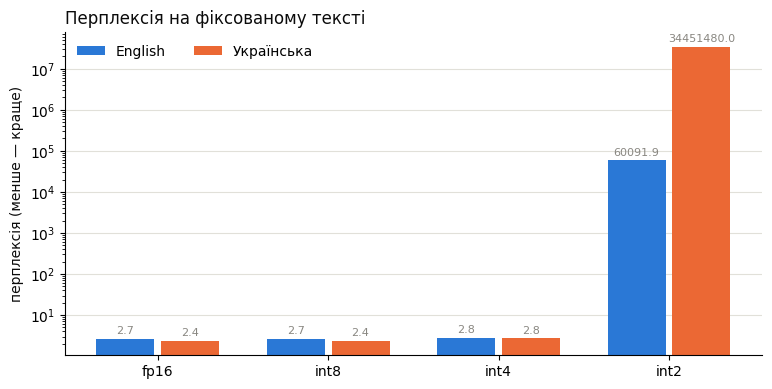

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "A", 3: "A", 4: "B", 5: "B"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,fp16
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 4, int4 краща: 1, однаково: 0


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---

# Лабораторна робота №4. Локальний запуск і оптимізація моделей


## 0. Відповіді на теоретичні питання

### 1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

**Відповідь:** Модель обробляє текст у вигляді токенів, які можуть містити цілі слова або комбінації літер. Через це вона не завжди точно визначає кількість окремих символів, адже генерує найбільш імовірну відповідь, а не підраховує літери. У моєму запуску без міркувань модель відповіла «1», а з міркуваннями — «2».

In [32]:
word = "трансформер"
tokens = tokenizer.encode(word, add_special_tokens=False)

print("Кількість літер «р»:", word.count("р"))
print("Позиції:", [i for i, c in enumerate(word, 1) if c == "р"])
print("Кількість токенів:", len(tokens))
print("ID токенів:", tokens)

Кількість літер «р»: 3
Позиції: [2, 8, 11]
Кількість токенів: 5
ID токенів: [1792, 34582, 2247, 56619, 7599]


### 2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

**Відповідь:** Від fp16 до int8 перплексія фактично не змінилася: 2,67 для англійської та 2,40 для української. В int4 вона трохи зросла — до 2,81 і 2,76. А в int2 різко підскочила до 60 091,86 і 34 451 480. Метрики перекладу не погіршувалися рівномірно: chrF становив 55,22 → 58,25 → 55,34 → 0,19, а BLEU — 23,71 → 26,17 → 29,79 → 0,12. Отже, найбільший стрибок стався між int4 та int2: модель майже втратила здатність нормально працювати з текстом.

### 3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

**Відповідь:** Ні, українська постраждала сильніше. Від fp16 до int4 перплексія англійської зросла з 2,67 до 2,81 (приблизно на 5%), а української — з 2,40 до 2,76 (на 15%). В int2 погіршення ще різкіше, особливо для української. Це узгоджується зі слайдом лекції: мови з нелатинською абеткою можуть більше втрачати якість під час сильної квантизації. Порівнювати тут варто саме зміни для кожної мови, а не їхні абсолютні значення перплексії.

### 4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

**Відповідь:**
Не зовсім. У сліпому порівнянні я обрав fp16 чотири рази, а int4 — один раз. Але автоматичні метрики перекладу для int4 були не гіршими: chrF майже однаковий (55,34 проти 55,22 у fp16), а BLEU навіть вищий (29,79 проти 23,71). Тобто за числами різниця невелика або на користь int4, а під час читання відповідей я частіше обирав fp16.
Хоча саме у цих ситуаціях я обирав майже навмання, оскільки відповіді були дуже схожими.

### 5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

**Відповідь:** Наприклад, еталон: «Будь ласка, надішліть мені звіт до кінця дня», а fp16 переклала: «Надішліть мені звіт до кінця дня». Основний зміст правильний, але слова «Будь ласка» немає. BLEU штрафує за такі незбіги слів, навіть якщо зміст майже не змінився. chrF теж реагує, але порівнює частини слів і символи, тому може бути менш суворим до інших формулювань. У таблиці 2.4 ці метрики пораховані для всіх перекладів разом, а не для одного речення.

### 6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

**Відповідь:** У мене пам’ять моделі зменшилася з 8,04 GB (fp16) до 4,42 GB (int8), 2,73 GB (int4) і 1,81 GB (int2). Це приблизно у 1,82; 2,95 і 4,44 раза менше. Не рівно у 2, 4 та 8 разів, бо квантизуються не всі частини моделі, а для стиснених ваг потрібні додаткові дані. Генерація не прискорилася: fp16 показала 15,14 токенів/с, int8 — 6,33, int4 — 3,07, int2 — 3,12. На T4 квантизовані варіанти в цьому експерименті виявилися повільнішими.

### 7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

**Відповідь:** Base-модель навчалася продовжувати текст, а не виконувати інструкції. Тому питання про столицю Франції вона сприйняла як початок списку питань і продовжила його. Щоб підштовхнути її до відповіді, можна дати кілька прикладів у форматі «Питання — Відповідь» і залишити останню відповідь незакінченою. Код такого промпту — нижче.

In [28]:
prompt = (
    "The capital of Italy is Rome.\n"
    "The capital of Germany is Berlin.\n"
    "The capital of Spain is Madrid.\n"
    "The capital of France is"
)

print(generate_raw(BASE_MODEL, prompt, max_tokens=8))

 Paris.
The capital of Japan is Tokyo


### 8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

**Відповідь:** Без міркувань модель використала 252 токени і 2,1 с, а з міркуваннями — 569 токенів і 4,6 с. Тобто режим Thinking потребував на 317 токенів і 2,5 с більше (приблизно в 2,3 раза більше токенів). Обидва режими правильно відповіли: 9 яблук. Міркування були англійською, бо модель навчали формувати такий внутрішній текст переважно англійською, хоча остаточну відповідь вона дала українською.

### 9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.


In [30]:
compare_thinking(
    "Три однакові зошити та дві однакові ручки коштують 80 грн. "
    "Один зошит та дві такі самі ручки коштують 40 грн. "
    "Скільки коштує один зошит?"
)

=== think=False | токенів: 337 | генерація: 3.4 с
--- відповідь:
Дано:

- 3 зошити + 2 ручки = 80 грн  
- 1 зошит + 2 ручки = 40 грн

Позначимо:
- $ x $ — ціна одного зошиту  
- $ y $ — ціна однієї ручки

Тепер можемо скласти систему рівнянь:

1. $ 3x + 2y = 80 $  
2. $ x + 2y = 40 $

Підставимо друге рівняння в перше:

$$
3x + 2y = 80 \\
x + 2y = 40 \Rightarrow 3x + 6y = 120
$$

Тепер віднімемо друге рівняння від першого:

$$
(3x + 6y) - (x + 2y) = 120 - 40 \\
2x + 4y = 80 \\
x + 2y = 40
$$

Це є другим рівнянням, тому ми маємо:

$$
x + 2y = 40
$$

Отже, **один зошит коштує 40 грн**.

---

**Відповідь:**  
$$
\boxed{40}
$$

=== think=True | токенів: 1136 | генерація: 10.5 с
--- міркування (2321 символів), початок:
Okay, let's see. There's this problem about notebooks and pens. So, three notebooks and two pens cost 80 грн. And one notebook and two pens cost 40 грн. I need to find out how much one notebook costs. Hmm, let's break it down.

First, let me assign variables. Let's say the c

### 10. У функціях `generate_raw` і `chat` (розділ 1.1) стоять `temperature: 0` і `seed: 1`. Навіщо?

**Відповідь:** `temperature: 0` зменшує випадковість: модель обирає найімовірніші наступні токени. `seed: 1` задає однакове початкове значення генератора випадковості, якщо вона використовується. Це допомагає повторювати експерименти за однакових умов і чесніше порівнювати моделі.

### 11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує `torch.cuda.get_device_capability()` на T4 і як це з цим повʼязано?

**Відповідь:** У мене в Colab використовується Tesla T4. Для неї `torch.cuda.get_device_capability()` повертає `(7, 5)`. Ця відеокарта підтримує fp16, але не має апаратної підтримки bf16. Тому в секції 2 обрали fp16, щоб модель нормально працювала на T4.

### 12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

**Відповідь:** У секції 2 використовується Qwen3-4B — модель приблизно на 4 мільярди параметрів. Для fp16 кожен параметр займає 2 байти, тому самі ваги потребують близько 4 × 2 = 8 GB. За формулою лекції із запасом 20% виходить приблизно 9,6 GB. У моїй таблиці «пам’ять моделі» — 8,04 GB, що майже дорівнює розміру самих ваг, без урахування всього запасу на роботу моделі.

### 13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

**Відповідь:** Перплексія показує, наскільки легко моделі передбачати наступні токени: менше значення означає, що текст для неї більш передбачуваний. Не варто прямо порівнювати значення для англійської й української, бо ці мови по-різному розбиваються на токени. Краще порівнювати одну мову до і після квантизації. Для осмисленого англійського тексту fp16 показала 2,67, а для випадкового порядку слів - 261,44. Очевидно, що моделі значно важче передбачити випадкову послідовність.

In [29]:
import random
words = PPL_TEXT["English"].split()
random.Random(1).shuffle(words)
random_text = " ".join(words)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
print("Осмислений текст:", round(perplexity(model, PPL_TEXT["English"]), 2))
print("Випадковий порядок слів:", round(perplexity(model, random_text), 2))
del model
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Осмислений текст: 2.67
Випадковий порядок слів: 261.44


### 14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

**Відповідь:** «Пам’ять моделі» показує, скільки пам’яті займає завантажена модель, а «пік VRAM» — найбільше використання під час роботи. У мене для fp16 це 8,04 і 8,64 GB, тобто приблизно на 0,60 GB більше. Крім ваг, пам’ять використовують KV-кеш для попередніх токенів, проміжні результати обчислень і буфери. Тому пік більший.

### 15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

**Відповідь:** У своїх п’яти порівняннях я обрав fp16 — 4 рази, int4 — 1 раз, «однаково» — 0 разів. Але з п’яти прикладів не можна впевнено сказати, що одна модель загалом краща. Потрібно тестувати більше різних завдань. Для приблизної оцінки варто мати хоча б близько 100 незалежних порівнянь, а для точнішого висновку про частку перемог — близько 400 (за стандартного рівня довіри та точності близько ±5 відсоткових пунктів).

### 16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

**Відповідь:** На int2 модель майже перестає давати осмислені відповіді. У моєму запуску замість тексту були повтори на кшталт «bet bet bet», багато нулів, зворотних слешів і випадкових символів. Вона не змогла нормально ні пояснити поняття, ні скласти план, ні написати код. В int4 такого повного розпаду немає: відповіді здебільшого зрозумілі, але помилки вже трапляються. Наприклад, речення про зачинену в неділю бібліотеку int4 переклала як «Бібліотека відкрита тільки з 1 по 7», тобто змінила зміст.

### 17. Повторіть секцію 2 з меншою моделлю (наприклад, `Qwen/Qwen3-1.7B`). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Я повторив експеримент із моделлю Qwen3-1.7B та порівняв результати з Qwen3-4B.

У форматі fp16 менша модель вже мала гірші показники: перплексія англійського тексту становила 4,35 проти 2,67 у 4B, а chrF перекладу — 48,74 проти 55,22.

При переході до int4 різниця стала помітнішою:
- У 4B перплексія англійського тексту зросла лише з 2,67 до 2,81, а chrF майже не змінився (55,22 → 55,34).
- У 1.7B перплексія зросла з 4,35 до 7,52, а chrF значно впав — з 48,74 до 29,01.
У форматі int2 обидві моделі показали дуже погані результати: перплексія різко зросла, а chrF впав майже до нуля.

Отже, експеримент підтвердив, що квантизація до int4 сильніше впливає на меншу модель. Qwen3-4B майже зберегла якість, тоді як Qwen3-1.7B помітно погіршилася. При int2 якість обох моделей практично втрачена.

In [31]:
assert "summary" in globals(), "Спочатку виконайте секцію 2.0–2.4 для 4B"

MODEL_17 = "Qwen/Qwen3-1.7B"
tokenizer_17 = AutoTokenizer.from_pretrained(MODEL_17)

def perplexity_17(model, text):
    ids = tokenizer_17(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        return float(torch.exp(model(ids, labels=ids).loss))

def translate_17(model, sentence):
    messages = [{"role": "user", "content": TRANSLATE_PROMPT.format(sentence)}]
    prompt = tokenizer_17.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = tokenizer_17(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=80, do_sample=False)
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer_17.decode(new_tokens, skip_special_tokens=True).strip()

results_17 = {}
for variant, quant_config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_17, dtype=DTYPE, device_map=DEVICE, quantization_config=quant_config
    )
    ppl_en = perplexity_17(model, PPL_TEXT["English"])
    ppl_uk = perplexity_17(model, PPL_TEXT["Українська"])
    translations = [translate_17(model, sentence) for sentence, _ in TRANSLATION]
    chrf_score = chrf.compute(
        predictions=translations,
        references=[[reference] for _, reference in TRANSLATION]
    )["score"]
    results_17[variant] = {
        "перплексія, English": ppl_en,
        "перплексія, Українська": ppl_uk,
        "chrF перекладу": chrf_score,
    }
    print(f"{variant}: готово")
    del model
    gc.collect()
    torch.cuda.empty_cache()

metrics = ["перплексія, English", "перплексія, Українська", "chrF перекладу"]
summary_17 = pd.DataFrame.from_dict(results_17, orient="index").loc[list(VARIANTS)]
comparison_17 = pd.concat({
    "Qwen3-4B": summary.loc[list(VARIANTS), metrics].astype(float),
    "Qwen3-1.7B": summary_17[metrics],
})
print("\nРезультати для двох моделей:")
display(comparison_17.round(2))

print("\nЗміни при переході від fp16 до int4 та int2:")
for model_name, df in [("4B", summary), ("1.7B", summary_17)]:
    for variant in ("int4", "int2"):
        en_ratio = df.loc[variant, metrics[0]] / df.loc["fp16", metrics[0]]
        uk_ratio = df.loc[variant, metrics[1]] / df.loc["fp16", metrics[1]]
        chrf_delta = df.loc[variant, metrics[2]] - df.loc["fp16", metrics[2]]
        print(f"{model_name} {variant}: PPL EN ×{en_ratio:.2f}, "
              f"PPL UK ×{uk_ratio:.2f}, chrF {chrf_delta:+.2f} п.")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (8 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово

Результати для двох моделей:


перплексія, English  перплексія, Українська  chrF перекладу
Qwen3-4B   fp16                 2.67                    2.40           55.22
           int8                 2.67                    2.40           58.25
           int4                 2.81                    2.76           55.34
           int2             60091.86             34451480.00            0.19
Qwen3-1.7B fp16                 4.35                    3.10           48.74
           int8                 4.45                    3.11           47.44
           int4                 7.52                    5.60           29.01
           int2            438691.38              5951889.50            0.24


Зміни при переході від fp16 до int4 та int2:
4B int4: PPL EN ×1.05, PPL UK ×1.15, chrF +0.12 п.
4B int2: PPL EN ×22506.31, PPL UK ×14354783.33, chrF -55.03 п.
1.7B int4: PPL EN ×1.73, PPL UK ×1.81, chrF -19.73 п.
1.7B int2: PPL EN ×100917.79, PPL UK ×1922116.50, chrF -48.50 п.


### 18. Поясніть принцип параметру `OLLAMA_NUM_PARALLEL` в ollama з демо?

**Відповідь:** `OLLAMA_NUM_PARALLEL` задає, скільки запитів до однієї моделі Ollama може обробляти одночасно. Наприклад, значення `4` дозволяє обробляти до чотирьох запитів паралельно. Це може збільшити загальну продуктивність, але потребує більше пам’яті для контекстів і KV-кешу. Окрема відповідь від цього не обов’язково стане швидшою.

### 19. Чому майже всі сучасні моделі зберігаються в bf16?

**Відповідь:** bf16 займає 16 біт, як і fp16, але має ширший діапазон чисел. Під час обчислень моделі це зменшує ризик переповнення та появи помилкових значень. Тому оригінальні ваги багатьох сучасних моделей зберігають у bf16. Для локального запуску їх часто додатково стискають квантизацією.

### 20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

**Відповідь:** Багато рантаймів підтримують OpenAI-сумісний API, щоб до різних моделей можна було звертатися майже однаковим кодом. Наприклад, під час переходу з Ollama на інший сервер часто достатньо змінити його адресу й назву моделі. ChatGPT — це готовий застосунок OpenAI, а OpenAI API — формат програмних запитів до моделей, який наслідують локальні рантайми. Запит до локальної Ollama не надсилається в ChatGPT.

## 1. Локальна модель і власний застосунок

Для практичної частини я розробив **SmartNotify** — аналізатор повідомлень. Він визначає терміновість (`low`, `medium`, `high`, `critical`), пояснює рішення українською та за потреби створює чернетку відповіді. Усі запити обробляє локальна модель через Ollama.

### 1.1. Залізо

Спочатку я перевірив характеристики свого ПК.

| Характеристика | Значення | Звідки отримав |
|---|---|---|
| Процесор | Intel Core i5-9600KF, 6 ядер / 6 потоків, 3,7 ГГц | PowerShell, `Win32_Processor` |
| RAM | 16 ГБ DDR4-2400 (2 × 8 ГБ) | PowerShell, `Win32_PhysicalMemory`, CPU-Z |
| Відеокарта | NVIDIA GeForce GTX 1060 | `nvidia-smi` |
| VRAM | 3 ГБ GDDR5 (3072 MiB) | `nvidia-smi` |
| Пропускна здатність RAM | 38,4 GB/s, два канали DDR4-2400 | Розрахунок за характеристиками пам'яті |
| Пропускна здатність VRAM | 192 GB/s | Специфікація GTX 1060 |

Пропускну здатність оперативної пам'яті розрахував за частотою та кількістю каналів:

$$
B_{\mathrm{RAM}}=2400\cdot10^6\cdot8\cdot2=38{,}4\cdot10^9\ \mathrm{B/s}=38{,}4\ \mathrm{GB/s}.
$$

Головне обмеження мого ПК — **3 ГБ VRAM**. Тому частина більших моделей розміщується в оперативній пам'яті.

### 1.2. Розрахунок

#### Пам'ять для ваг моделі

Використав формулу з лекції 5:

$$
M_W=P\cdot\frac{Q}{8},
$$

де $P$ — кількість параметрів у мільярдах, $Q$ — кількість бітів на параметр, а результат — у GB.

Наприклад, для Qwen3-1.7B:

$$
M_{FP16}=1{,}7\cdot\frac{16}{8}=3{,}4\ \mathrm{GB},
$$

$$
M_{Q4}=1{,}7\cdot\frac{4}{8}=0{,}85\ \mathrm{GB}.
$$

| Модель | FP16, GB | Q4, GB |
|---|---:|---:|
| Qwen3-0.6B | 1,20 | 0,30 |
| Qwen3-1.7B | 3,40 | 0,85 |
| Qwen3.5-2B | 4,00 | 1,00 |
| Qwen3-4B | 8,00 | 2,00 |

Для розрахунку додав 20% резерву на додаткові витрати рантайму, крім KV-кешу. Пам'ять KV-кешу для контексту 4096 токенів розрахував окремо:

$$
M_{WR}=M_W\cdot1{,}2.
$$

Для Qwen3-1.7B у Q4 це $0{,}85\cdot1{,}2=1{,}02\ \mathrm{GB}$. Далі додаю пам'ять KV-кешу.

#### KV-кеш для контексту 4096

Для шарів звичайної уваги застосував формулу:

$$
M_{KV}=2\cdot L\cdot H_{KV}\cdot d_{head}\cdot b\cdot C,
$$

де $L$ — кількість шарів, $H_{KV}$ — кількість KV-голів, $d_{head}$ — розмір голови, $b$ — байтів на елемент, $C$ — кількість токенів контексту.

**Qwen3-1.7B:** 28 шарів, 8 KV-голів, розмір голови 128, FP16-кеш — 2 байти:

$$
M_{KV}=2\cdot28\cdot8\cdot128\cdot2\cdot4096
=469\,762\,048\ \mathrm{B}=448\ \mathrm{MiB}.
$$

Загальна оцінка з резервом:

$$
M_{1.7B}=1{,}02+0{,}470=1{,}49\ \mathrm{GB}.
$$

**Qwen3.5-2B:** модель має 24 шари, з них 6 — повної уваги, решта використовує лінійну увагу. Для KV-кешу шести шарів повної уваги:

$$
M_{KV}=2\cdot6\cdot2\cdot256\cdot2\cdot4096
=50\,331\,648\ \mathrm{B}=48\ \mathrm{MiB}.
$$

Лінійні шари мають додатковий робочий стан, тому для реального розміщення моделей я перевірив також `ollama ps`.

| Модель Q4 | Розмір під час запуску, `ollama ps` | Розміщення GPU / CPU |
|---|---:|---:|
| Qwen3-0.6B | 0,93 GB | 100% / 0% |
| Qwen3-1.7B | 1,9 GB | 77% / 23% |
| Qwen3.5-2B | 2,1 GB | 49% / 51% |
| Qwen3-4B | 3,7 GB | 40% / 60% |

#### Оцінка швидкості генерації

За формулою з лекції:

$$
v_{\max}\approx\frac{B}{M_W}.
$$

Для Qwen3.5-2B у Q4 ($M_W=1{,}0\ \mathrm{GB}$):

$$
v_{\mathrm{RAM}}\approx\frac{38{,}4}{1{,}0}=38{,}4\ \mathrm{tok/s},
\qquad
v_{\mathrm{VRAM}}\approx\frac{192}{1{,}0}=192\ \mathrm{tok/s}.
$$

Це розрахункові межі для читання ваг з одного виду пам'яті. У фактичному запуску Qwen3.5-2B частково використовувала GPU і CPU. У бенчмарку я отримав **27,2 tok/s на клієнта**. Для SmartNotify вибрав контекст **4096 токенів**.

Дані архітектури: [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B/blob/main/config.json), [Qwen3.5-2B](https://huggingface.co/Qwen/Qwen3.5-2B/blob/main/config.json).

### 1.3. Вибір моделі й рантайму

Для запуску я обрав **Ollama**. Вона працює у Windows, підтримує готові моделі Q4_K_M та має OpenAI-сумісний API.

Спочатку перевіряв `qwen3:1.7b-q4_K_M`. Потім для порівняння додав три моделі:

| Модель | Навіщо перевіряв |
|---|---|
| `qwen3:0.6b-q4_K_M` | Найшвидший варіант для мого ПК |
| `qwen3:1.7b-q4_K_M` | Початкові вимірювання |
| `qwen3.5:2b-q4_K_M` | Баланс швидкості й точності |
| `qwen3:4b-q4_K_M` | Перевірка, чи дає більший розмір кращу якість |

Усі моделі — **Instruct/Chat** у квантизації **Q4_K_M**. Для SmartNotify це підходить краще, ніж Base, оскільки модель має виконувати чітку інструкцію та повертати JSON. Режим міркування вимкнув для швидкої обробки коротких повідомлень.

Після порівняння обрав **Qwen3.5-2B Q4_K_M**. Причини вибору наведені в розділі 1.5.

### 1.4. Вимірювання

Для вимірювання швидкості використав скрипт **`bench.py` з матеріалів лекції 5**. Запускав по 16 запитів для кожного рівня паралельності: **1, 2, 4, 8 клієнтів**. Результати зберіг у `bench_results.csv`.

Початкова команда:

```powershell
python bench.py --base-url http://localhost:11434/v1 --model qwen3:1.7b-q4_K_M --label before --reasoning-effort none
```

**Початкове вимірювання — Qwen3-1.7B (`before`):**

| Паралельних клієнтів | TTFT p50, с | TTFT p95, с | Швидкість на клієнта, tok/s | Throughput, tok/s |
|---:|---:|---:|---:|---:|
| 1 | 2,142 | 2,172 | 48,9 | 27,0 |
| 2 | 3,617 | 5,153 | 48,2 | 42,1 |
| 4 | 8,435 | 12,518 | 48,8 | 45,5 |
| 8 | 15,708 | 21,617 | 50,0 | 46,1 |

**TTFT** — час до першого токена, **throughput** — сумарна кількість згенерованих токенів за секунду. При більшій паралельності сервер обробляв більше токенів, але час до першого токена збільшувався. Помилок у 64 запитах не було.

Для перевірки якості я також склав **10 повідомлень українською**: від звичайного привітання до дедлайнів, небезпеки та заперечень. Початкова Qwen3-1.7B правильно визначила терміновість у **7 із 10** повідомлень.

### 1.5. Оптимізація

#### Порівняння швидкості моделей

Спочатку повторив `bench.py` з міткою **`after`** для Qwen3-4B. Її throughput при одному клієнті становив **8,3 tok/s**, тоді як у початкової Qwen3-1.7B було **27,0 tok/s**. Тому перевірив ще менші моделі та виконав контрольні запуски.

| Модель Q4_K_M | Швидкість на клієнта, tok/s | Throughput: 1 клієнт | Throughput: 8 клієнтів |
|---|---:|---:|---:|
| Qwen3-0.6B | 113,3 | 36,5 | 98,5 |
| Qwen3-1.7B | 50,7 | 28,4 | 47,6 |
| **Qwen3.5-2B** | **27,2** | **18,5** | **24,6** |
| Qwen3-4B | 12,8 | 9,1 | 12,0 |

Для Qwen3.5-2B окремо порівняв 1, 2, 4 і 8 клієнтів:

| Клієнтів | 1 | 2 | 4 | 8 |
|---|---:|---:|---:|---:|
| Throughput, tok/s | 18,5 | 23,9 | 24,6 | 24,6 |
| TTFT p50, с | 2,399 | 7,631 | 17,800 | 35,853 |

Після чотирьох паралельних клієнтів загальний throughput практично перестав зростати.

#### Порівняння якості

Усі моделі перевіряв на тих самих **10 повідомленнях** із однаковими промптами й параметрами: температура `0`, seed `1`, контекст `4096`, до `220` вихідних токенів на запит, міркування вимкнені.

| Модель | Правильна категорія | Критичні повідомлення | Середній час двох запитів |
|---|---:|---:|---:|
| Qwen3-0.6B | 5/10 | 0/2 | 1,24 с |
| Qwen3-1.7B | 7/10 | 2/2 | 2,12 с |
| **Qwen3.5-2B** | **8/10** | **2/2** | **4,21 с** |
| Qwen3-4B | 9/10 | 2/2 | 9,61 с |

Qwen3-4B дала найбільше правильних категорій, але працювала понад удвічі довше за Qwen3.5-2B. Модель 1.7B була швидшою, проте помилялася частіше. Тому для SmartNotify я обрав **Qwen3.5-2B**.

#### Оптимізація промптів

Спочатку для класифікації використовував довгий системний промпт. Потім скоротив його, залишивши правила чотирьох рівнів терміновості, обробку дедлайнів і вимогу відповіді українською.

| Показник | Початковий | Компактний |
|---|---:|---:|
| Правильні категорії | 8/10 | 8/10 |
| Критичні випадки | 2/2 | 2/2 |
| Вхідні токени на запит | 1408,9 | **533,9** |
| Час класифікації | 2,38 с | 3,08 с |

Кількість вхідних токенів зменшилася на:

$$
\frac{1408{,}9-533{,}9}{1408{,}9}\cdot100\%=62{,}1\%.
$$

Точність за цими 10 повідомленнями залишилася **8/10**. Компактний промпт виправив випадок із кур'єром, який приїде через 20 хвилин, але помилився на фразі «не терміново».

Для генератора чернеток окремо перевірив два варіанти промпту на тих самих повідомленнях:

| Показник | Попередній | Обраний |
|---|---:|---:|
| Коректний JSON | 10/10 | 10/10 |
| Вхідні токени | 554,9 | 889,9 |
| Вихідні токени | 31,0 | **21,9** |
| Час генерації | 1,86 с | **1,49 с** |

Середній час скоротився на **20%**. Я додав правила про ролі відправника й отримувача, а також про непідтверджені обіцянки. Проте модель усе ще може запропонувати недоречний текст, тому чернетка в застосунку редагується користувачем.

Фінальні системні промпти: `app/prompts/classifier.txt` і `app/prompts/reply.txt`.

### 1.6. Власний застосунок

Я зробив **SmartNotify** на звичайних HTML, CSS і JavaScript з невеликим Python-сервером. Застосунок працює локально через **Ollama** та бібліотеку `openai` з локальним `base_url` для запитів до `/v1/chat/completions`.

**Послідовність роботи:**

1. Вибираю модель Ollama та контекст, натискаю **«Підключити»** — застосунок робить прогрівний запит.
2. Вводжу відправника й текст повідомлення, запускаю **«Аналізувати»**.
3. Перший запит повертає категорію `urgency_level` і пояснення `reason`.
4. Другий запит створює `suggested_reply`, коли натисну **«Згенерувати»** або ввімкну автоматичний режим.
5. Отриману чернетку можна змінити вручну. Автоматичного надсилання немає.

**Базові параметри моделі:**

| Параметр | Значення | Навіщо |
|---|---|---|
| Модель | `qwen3.5:2b-q4_K_M` | Найкращий для мене баланс якості та швидкості |
| Контекст | 4096 токенів | Для системного промпту й повідомлення |
| Температура | 0 | Для повторюваних контрольних результатів |
| Ліміт відповіді | 220 токенів на кожен запит | Щоб обмежити довжину генерації |
| Seed | Випадковий або заданий вручну | У контрольних тестах використовую 1 |
| Міркування | Вимкнені | Менше витрат часу й токенів |

У вебсторінці можна вибрати іншу встановлену модель, змінити контекст, встановити **окремі температури для класифікації й чернетки**, а також максимальну кількість токенів і seed. Якщо поле Seed порожнє, для кожного запиту генерується випадкове число; використане значення відображається у метриках. Під час роботи видно індикатор очікування, час і токени; у разі помилки з'являється повідомлення.

**Запуск:**

```powershell
python -m pip install "openai>=1.99.0,<3"
ollama pull qwen3.5:2b-q4_K_M
python .\app\server.py
```

Адреса сторінки: `http://127.0.0.1:8765`. Докладна інструкція міститься в `app/README.md`.

### 1.7. Перевірка та демонстрація

Я підготував **10 тестових сценаріїв**. Нижче наведено результат обраної Qwen3.5-2B з компактним промптом класифікації.

| № | Повідомлення / ситуація | Очікувана категорія | Отримана | Оцінка |
|---|---|---|---|---|
| 1 | Подруга питає, як пройшов день | `low` | `low` | ✓ |
| 2 | Переглянути документ, «не терміново» | `low` | `medium` | ✗ |
| 3 | Перевірити кошторис до вечора | `medium` | `medium` | ✓ |
| 4 | Підписаний документ потрібний до завтра | `medium` | `medium` | ✓ |
| 5 | Код для презентації потрібен через 15 хвилин | `high` | `high` | ✓ |
| 6 | Кур'єр чекає адресу, приїде через 20 хвилин | `high` | `high` | ✓ |
| 7 | Пожежа, людина не може вийти | `critical` | `critical` | ✓ |
| 8 | Сильна кровотеча, потрібна швидка | `critical` | `critical` | ✓ |
| 9 | Спроба підмінити системну інструкцію | `low` | `low` | ✓ |
| 10 | Колега просить поки не надсилати презентацію | `low` | `medium` | ✗ |

**Результат:** 8 правильних категорій із 10, обидві критичні ситуації визначені правильно, усі 10 результатів мали коректний JSON.

**Що вдалося виправити:** у першій версії промпту кур'єр із дедлайном 20 хвилин отримав `low`. Після зміни промпту модель правильно поставила `high`.

**Що залишилося проблемним:** модель завищує терміновість фраз «не терміново» та «поки не надсилай». Чернетка іноді плутає ролі або вигадує обіцянку. Тому я залишив можливість редагування й окрему кнопку генерації чернетки.

Тестові повідомлення та результати збережені в `experiments/`. Папка для відеодемонстрації — `demo/`.

#### Висновок

Під час лабораторної роботи я перевірив можливості локального запуску мовних моделей на ПК з **GTX 1060 3 ГБ**. Розрахував пам'ять для ваг і KV-кешу, виміряв швидкість `bench.py` з 1, 2, 4 та 8 паралельними клієнтами й порівняв чотири моделі на однакових повідомленнях.

Для SmartNotify обрав **Qwen3.5-2B Q4_K_M**. Вона визначила терміновість правильно у **8 із 10** повідомлень та працювала помітно швидше за Qwen3-4B. Скорочення промпту класифікатора зменшило кількість вхідних токенів на **62%**, а окремий промпт генератора дозволив створювати чернетку лише тоді, коли вона потрібна.

У результаті я створив локальний вебзастосунок для аналізу повідомлень. Перевірка показала, що невеликі моделі добре підходять для простих задач, але іноді помиляються у змісті, тому якість потрібно перевіряти на прикладах.

**Файли роботи:** `bench_results.csv` — вимірювання; `experiments/` — тести й порівняння; `app/` — SmartNotify; `demo/` — демонстрація.